# Diagnostic-overlap sensitivity analysis

This notebook compares the original heterogeneous cohort with a restricted cohort excluding:

- 16 participants classified as `NotAphasicbyWAB` from the aphasia group
- 34 participants classified as `PPA` from the dementia group

Both conditions use the same saved $k=1$ fold features, original train/test fold assignments, feature-selection rule, scaling, and multinomial logistic-regression specification. Only cohort membership changes. This design isolates sensitivity to diagnostic overlap; it does not regenerate embeddings, cutoffs, or participant features.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

sns.set_theme(style='whitegrid')

cwd = Path.cwd().resolve()
repo_root = cwd if (cwd / 'data').exists() else cwd.parent
fold_dir = repo_root / 'data' / 'classification' / 'fold_features_traincutoff_designB'
metadata_path = repo_root / 'data' / 'classification' / 'combined_patient_data_111725.csv'

fold_dir, metadata_path

(PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/data/classification/fold_features_traincutoff_designB'),
 PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/data/classification/combined_patient_data_111725.csv'))

## Model specification

The feature rule below follows the ratio-based classification notebook: raw `num_` counts and total utterance count are excluded, along with the previously removed correlated ratio variables. If the final manuscript model uses a different feature list, edit `FEATURES_TO_REMOVE` before running the comparison. The same resulting feature list is always used in both conditions.

In [2]:
K = 1.0
LR_MAX_ITER = 500
RANDOM_STATE = 42

LABEL_TO_INT = {'controls': 0, 'aphasia': 1, 'dementia': 2}
CLASS_NAMES = ['Control', 'Aphasia', 'Dementia']
PAIR_SPECS = {
    'control_aphasia_auc': (0, 1),
    'control_dementia_auc': (0, 2),
    'aphasia_dementia_auc': (1, 2),
}

METADATA_COLUMNS = {
    'fold', 'split', 'cutoff_from', 'cutoff', 'participant', 'label'
}
FEATURES_TO_REMOVE = {
    'total_utterances',
    'total_main_concept_match_ratio',
    'ratio_missing_referent_percent',
    'ratio_conceptual_incongruence_percent',
}

def normalize_id(values):
    return values.astype(str).str.strip().str.lower()

def find_fold_pairs(folder, k):
    pairs = []
    for train_path in sorted(folder.glob(f'fold*_train_features_traincutoff_k{k}.csv')):
        match = re.search(r'fold(\d+)_train_', train_path.name)
        if match is None:
            continue
        fold = int(match.group(1))
        test_path = folder / train_path.name.replace('_train_', '_test_')
        if not test_path.exists():
            raise FileNotFoundError(test_path)
        pairs.append((fold, train_path, test_path))
    if not pairs:
        raise FileNotFoundError(f'No fold files found in {folder} for k={k}')
    return pairs

fold_pairs = find_fold_pairs(fold_dir, K)
[(fold, train.name, test.name) for fold, train, test in fold_pairs]

[(0,
  'fold00_train_features_traincutoff_k1.0.csv',
  'fold00_test_features_traincutoff_k1.0.csv'),
 (1,
  'fold01_train_features_traincutoff_k1.0.csv',
  'fold01_test_features_traincutoff_k1.0.csv'),
 (2,
  'fold02_train_features_traincutoff_k1.0.csv',
  'fold02_test_features_traincutoff_k1.0.csv'),
 (3,
  'fold03_train_features_traincutoff_k1.0.csv',
  'fold03_test_features_traincutoff_k1.0.csv'),
 (4,
  'fold04_train_features_traincutoff_k1.0.csv',
  'fold04_test_features_traincutoff_k1.0.csv')]

In [3]:
metadata = pd.read_csv(metadata_path, dtype=str)
metadata['participant_normalized'] = normalize_id(metadata['participant'])

# Some numeric participant IDs are reused across corpora. None of the
# participants targeted by this analysis has a duplicated normalized ID.
exclusion_mask = metadata['diagnosis'].isin(['NotAphasicbyWAB', 'PPA'])
excluded_metadata = metadata.loc[
    exclusion_mask,
    ['participant', 'participant_normalized', 'diagnosis', 'gen_diagnosis'],
].copy()
excluded_ids = set(excluded_metadata['participant_normalized'])
assert len(excluded_ids) == len(excluded_metadata), (
    'An excluded participant ID is duplicated in metadata'
)

exclusion_counts = (
    excluded_metadata.groupby(['gen_diagnosis', 'diagnosis'])
    .size()
    .rename('n_excluded')
    .reset_index()
)
assert len(excluded_ids) == 50, f'Expected 50 exclusions, found {len(excluded_ids)}'
assert (excluded_metadata['diagnosis'] == 'NotAphasicbyWAB').sum() == 16
assert (excluded_metadata['diagnosis'] == 'PPA').sum() == 34

exclusion_counts

,gen_diagnosis,diagnosis,n_excluded
0,Aphasia,NotAphasicbyWAB,16
1,Dementia,PPA,34


In [4]:
def select_feature_columns(df):
    columns = []
    for column in df.columns:
        if column in METADATA_COLUMNS:
            continue
        if column.startswith('num_'):
            continue
        if column in FEATURES_TO_REMOVE:
            continue
        columns.append(column)
    if not columns:
        raise ValueError('No feature columns selected')
    return columns

def prepare_features(df, feature_columns):
    return (
        df[feature_columns]
        .apply(pd.to_numeric, errors='coerce')
        .fillna(0.0)
    )

def make_model():
    return Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(
            solver='lbfgs',
            max_iter=LR_MAX_ITER,
            class_weight='balanced',
            random_state=RANDOM_STATE,
        )),
    ])

def evaluate_scenario(scenario, ids_to_exclude, feature_columns):
    fold_rows = []
    prediction_rows = []

    for fold, train_path, test_path in fold_pairs:
        train = pd.read_csv(train_path)
        test = pd.read_csv(test_path)
        train['participant_normalized'] = normalize_id(train['participant'])
        test['participant_normalized'] = normalize_id(test['participant'])

        n_train_before, n_test_before = len(train), len(test)
        train = train.loc[~train['participant_normalized'].isin(ids_to_exclude)].copy()
        test = test.loc[~test['participant_normalized'].isin(ids_to_exclude)].copy()

        X_train = prepare_features(train, feature_columns)
        X_test = prepare_features(test, feature_columns)
        y_train = train['label'].map(LABEL_TO_INT)
        y_test = test['label'].map(LABEL_TO_INT)
        assert y_train.notna().all() and y_test.notna().all()
        y_train = y_train.astype(int).to_numpy()
        y_test = y_test.astype(int).to_numpy()
        assert set(np.unique(y_train)) == {0, 1, 2}
        assert set(np.unique(y_test)) == {0, 1, 2}

        model = make_model()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        probabilities = model.predict_proba(X_test)
        classes = model.named_steps['lr'].classes_

        pairwise_aucs = {}
        for metric_name, (negative_class, positive_class) in PAIR_SPECS.items():
            pair_mask = np.isin(y_test, [negative_class, positive_class])
            positive_column = int(np.where(classes == positive_class)[0][0])
            pairwise_aucs[metric_name] = roc_auc_score(
                (y_test[pair_mask] == positive_class).astype(int),
                probabilities[pair_mask, positive_column],
            )

        fold_rows.append({
            'scenario': scenario,
            'fold': fold,
            'n_train': len(train),
            'n_test': len(test),
            'n_train_excluded': n_train_before - len(train),
            'n_test_excluded': n_test_before - len(test),
            'accuracy': accuracy_score(y_test, y_pred),
            'macro_f1': f1_score(y_test, y_pred, average='macro'),
            **pairwise_aucs,
        })

        prediction_rows.append(pd.DataFrame({
            'scenario': scenario,
            'fold': fold,
            'participant': test['participant'].astype(str).to_numpy(),
            'y_true': y_test,
            'y_pred': y_pred,
        }))

    fold_metrics = pd.DataFrame(fold_rows)
    predictions = pd.concat(prediction_rows, ignore_index=True)
    matrix = confusion_matrix(
        predictions['y_true'], predictions['y_pred'], labels=[0, 1, 2]
    )

    correct_by_class = matrix.diagonal()
    total_by_class = matrix.sum(axis=1)
    recall_by_class = correct_by_class / total_by_class

    summary = {
        'scenario': scenario,
        'n_test_participants': len(predictions),
        'mean_accuracy': fold_metrics['accuracy'].mean(),
        'sd_accuracy': fold_metrics['accuracy'].std(ddof=1),
        'pooled_accuracy': accuracy_score(predictions['y_true'], predictions['y_pred']),
        'mean_macro_f1': fold_metrics['macro_f1'].mean(),
        'sd_macro_f1': fold_metrics['macro_f1'].std(ddof=1),
        'pooled_macro_f1': f1_score(
            predictions['y_true'], predictions['y_pred'], average='macro'
        ),
        'control_recall': recall_by_class[0],
        'aphasia_recall': recall_by_class[1],
        'dementia_recall': recall_by_class[2],
        'control_correct': correct_by_class[0],
        'control_total': total_by_class[0],
        'aphasia_correct': correct_by_class[1],
        'aphasia_total': total_by_class[1],
        'dementia_correct': correct_by_class[2],
        'dementia_total': total_by_class[2],
        'mean_control_aphasia_auc': fold_metrics['control_aphasia_auc'].mean(),
        'sd_control_aphasia_auc': fold_metrics['control_aphasia_auc'].std(ddof=1),
        'mean_control_dementia_auc': fold_metrics['control_dementia_auc'].mean(),
        'sd_control_dementia_auc': fold_metrics['control_dementia_auc'].std(ddof=1),
        'mean_aphasia_dementia_auc': fold_metrics['aphasia_dementia_auc'].mean(),
        'sd_aphasia_dementia_auc': fold_metrics['aphasia_dementia_auc'].std(ddof=1),
    }
    return {
        'fold_metrics': fold_metrics,
        'predictions': predictions,
        'confusion_matrix': matrix,
        'summary': summary,
    }


In [5]:
first_train = pd.read_csv(fold_pairs[0][1])
feature_columns = select_feature_columns(first_train)
print(f'Number of model features: {len(feature_columns)}')
print(feature_columns)

full_result = evaluate_scenario(
    scenario='Full heterogeneous sample',
    ids_to_exclude=set(),
    feature_columns=feature_columns,
)
restricted_result = evaluate_scenario(
    scenario='Restricted sample',
    ids_to_exclude=excluded_ids,
    feature_columns=feature_columns,
)

fold_metrics = pd.concat([
    full_result['fold_metrics'],
    restricted_result['fold_metrics'],
], ignore_index=True)

assert restricted_result['fold_metrics']['n_test_excluded'].sum() == 50
fold_metrics.round(3)

Number of model features: 10
['distance_to_centroid', 'unique_main_concept_match_ratio', 'sequence_score_mainconcept', 'local_coherence_mainconcept', 'global_coherence_mainconcept', 'ratio_topic_switching_percent', 'ratio_tangential_utterance_percent', 'ratio_propositional_repetition_percent', 'ratio_filler_percent', 'ratio_coherent_percent']


,scenario,fold,n_train,n_test,n_train_excluded,n_test_excluded,accuracy,macro_f1,control_aphasia_auc,control_dementia_auc,aphasia_dementia_auc
0,Full heterogeneous sample,0,247,62,0,0,0.532,0.538,0.909,0.602,0.629
1,Full heterogeneous sample,1,247,62,0,0,0.661,0.619,0.964,0.693,0.686
2,Full heterogeneous sample,2,247,62,0,0,0.629,0.609,0.987,0.684,0.561
3,Full heterogeneous sample,3,247,62,0,0,0.597,0.585,0.883,0.673,0.545
4,Full heterogeneous sample,4,248,61,0,0,0.607,0.589,0.947,0.652,0.454
5,Restricted sample,0,205,54,42,8,0.630,0.620,0.954,0.542,0.838
6,Restricted sample,1,206,53,41,9,0.736,0.717,0.965,0.722,0.866
7,Restricted sample,2,209,50,38,12,0.740,0.692,0.982,0.709,0.871
8,Restricted sample,3,207,52,40,10,0.596,0.580,0.884,0.652,0.803
9,Restricted sample,4,209,50,39,11,0.680,0.657,0.969,0.729,0.890


In [6]:
summary = pd.DataFrame([
    full_result['summary'],
    restricted_result['summary'],
]).set_index('scenario')

# Primary table aligned with the manuscript: pooled overall accuracy,
# class-level recall, and mean fold AUC. Macro-F1 is retained as an
# additional sensitivity metric requested for this analysis.
metric_columns = [
    'n_test_participants',
    'pooled_accuracy',
    'control_recall',
    'aphasia_recall',
    'dementia_recall',
    'mean_control_aphasia_auc',
    'mean_control_dementia_auc',
    'mean_aphasia_dementia_auc',
    'mean_macro_f1',
    'pooled_macro_f1',
]
manuscript_metrics = summary[metric_columns].copy()
manuscript_comparison = manuscript_metrics.copy()
manuscript_comparison.loc['Restricted minus full'] = (
    manuscript_metrics.loc['Restricted sample']
    - manuscript_metrics.loc['Full heterogeneous sample']
)
manuscript_comparison.round(3)

,n_test_participants,pooled_accuracy,control_recall,aphasia_recall,dementia_recall,mean_control_aphasia_auc,mean_control_dementia_auc,mean_aphasia_dementia_auc,mean_macro_f1,pooled_macro_f1
scenario,,,,,,,,,,
Full heterogeneous sample,309.0,0.605,0.735,0.686,0.362,0.938,0.661,0.575,0.588,0.591
Restricted sample,259.0,0.676,0.646,0.849,0.483,0.951,0.671,0.854,0.653,0.657
Restricted minus full,-50.0,0.070,-0.088,0.163,0.122,0.013,0.010,0.279,0.065,0.066


In [7]:
class_recall_rows = []
for scenario in ['Full heterogeneous sample', 'Restricted sample']:
    row = summary.loc[scenario]
    for class_key, class_name in [
        ('control', 'Control'),
        ('aphasia', 'Aphasia'),
        ('dementia', 'Dementia'),
    ]:
        class_recall_rows.append({
            'scenario': scenario,
            'class': class_name,
            'correct': int(row[f'{class_key}_correct']),
            'total': int(row[f'{class_key}_total']),
            'recall': row[f'{class_key}_recall'],
        })
class_recall_table = pd.DataFrame(class_recall_rows)
class_recall_table.round(3)

,scenario,class,correct,total,recall
0,Full heterogeneous sample,Control,83,113,0.735
1,Full heterogeneous sample,Aphasia,70,102,0.686
2,Full heterogeneous sample,Dementia,34,94,0.362
3,Restricted sample,Control,73,113,0.646
4,Restricted sample,Aphasia,73,86,0.849
5,Restricted sample,Dementia,29,60,0.483


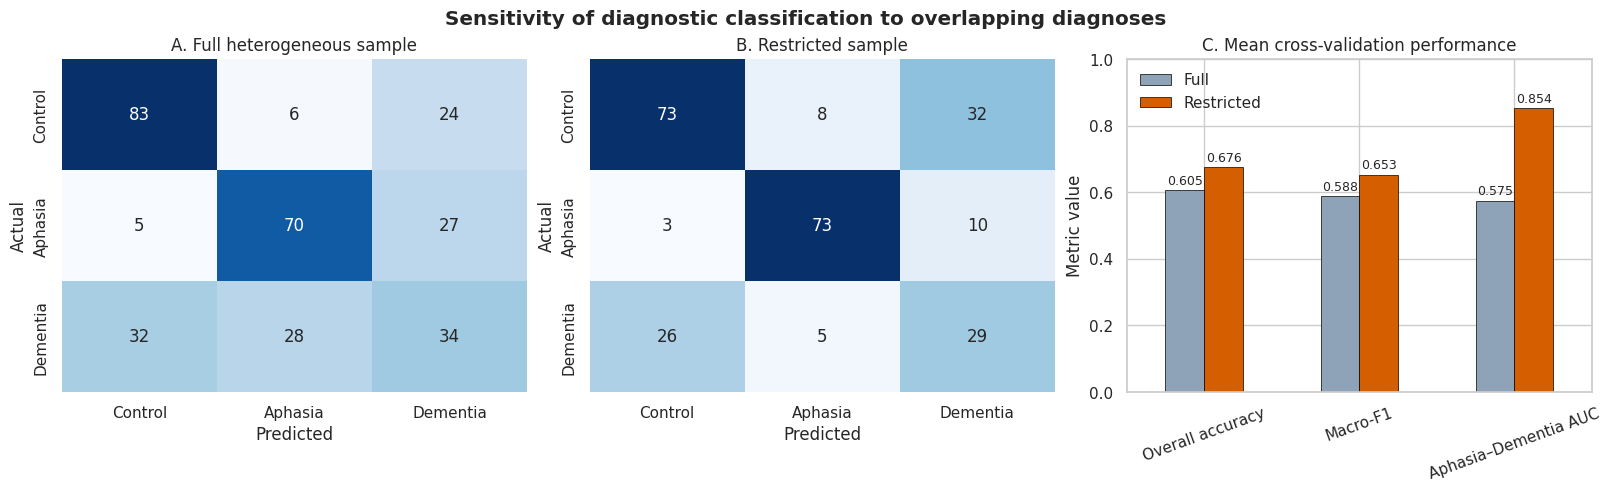

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for axis, result, title in [
    (axes[0], full_result, 'A. Full heterogeneous sample'),
    (axes[1], restricted_result, 'B. Restricted sample'),
]:
    sns.heatmap(
        result['confusion_matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel('Predicted')
    axis.set_ylabel('Actual')

plot_data = summary[[
    'pooled_accuracy', 'mean_macro_f1', 'mean_aphasia_dementia_auc'
]].rename(columns={
    'pooled_accuracy': 'Overall accuracy',
    'mean_macro_f1': 'Macro-F1',
    'mean_aphasia_dementia_auc': 'Aphasia–Dementia AUC',
})
plot_data.T.plot(
    kind='bar',
    color=['#8FA3B8', '#D55E00'],
    edgecolor='black',
    linewidth=0.5,
    ax=axes[2],
)
axes[2].set_ylim(0, 1)
axes[2].set_title('C. Mean cross-validation performance')
axes[2].set_ylabel('Metric value')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=20)
axes[2].legend(['Full', 'Restricted'], frameon=False, loc='upper left')

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.3f', padding=2, fontsize=9)

fig.suptitle('Sensitivity of diagnostic classification to overlapping diagnoses', fontweight='bold')
plt.show()

# Optional publication-quality output:
figure_path = repo_root / 'data' / 'classification' / 'diagnostic_overlap_sensitivity.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')

## Interpretation guidance

An improvement in the restricted analysis is consistent with diagnostic overlap contributing to classification difficulty. It does not prove that overlap is the only cause: sample size, age, corpus/site, severity, and other subtype differences may also change when these participants are excluded. The restricted analysis should therefore be presented as a sensitivity analysis rather than a replacement for the heterogeneous primary analysis.

In [10]:
# Optional: save the tables after reviewing the results.
output_dir = repo_root / 'data' / 'classification' / 'diagnostic_overlap_sensitivity'
output_dir.mkdir(parents=True, exist_ok=True)
manuscript_metrics.to_csv(output_dir / 'manuscript_aligned_summary.csv')
class_recall_table.to_csv(output_dir / 'class_recall_counts.csv', index=False)
summary.to_csv(output_dir / 'complete_summary.csv')
fold_metrics.to_csv(output_dir / 'fold_metrics.csv', index=False)
excluded_metadata.to_csv(output_dir / 'excluded_participants.csv', index=False)